# 1. Policy and information adjustment in German production

I compare the relative production response to the supplied policy component with the response to the recomposed rate surprise. The [primary specification](../docs/primary_specification.json) was committed before estimation. The [research design](../docs/research_design.md) and [source register](../docs/sources.md) distinguish this conditional projection from causal claims. A unit is a ten-basis-point factor contribution. I preserve the declared sensitivities and contrary or imprecise results.

In [1]:
from pathlib import Path
import csv
import sys
from IPython.display import Markdown, Image, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "scripts/local_projections.py").is_file())
sys.path.insert(0, str(ROOT / "scripts"))
from run_analysis import run
summary = run(ROOT / "reports/notebook_replay")
with (ROOT / "reports/notebook_replay/estimates.csv").open(newline="") as stream:
    rows = list(csv.DictReader(stream))
print("Pre-estimation specification:", summary["specification_commit"])
print("Primary sample:", summary["primary"]["first"], "to", summary["primary"]["last"], "n =", summary["primary"]["n"])

Pre-estimation specification: 66ed69c136b41d2775a62909375a4d1cd00ec048
Primary sample: 2000-01 to 2025-08 n = 308


## 2. Twelve-month comparison

The endpoint is twelve months after the announcement month relative to the preceding month, summing thirteen monthly changes. The policy-component coefficient is the companion estimand. The gap is the recomposed-rate coefficient less the policy-component coefficient on identical rows. Its primary interval maps a Bonferroni joint rectangle for the mixture weight and component-response difference; the normal gap interval is a regularity-dependent diagnostic.

In [2]:
primary = summary["primary"]
table = ["| Estimand | Estimate | Lower | Upper | Interval |", "| --- | ---: | ---: | ---: | --- |"]
for key, label in [("beta_m", "Policy response"), ("beta_c", "Information response"), ("gamma", "Recomposed-rate response")]:
    table.append(f"| {label} | {primary[key]:.3f} | {primary[key+'_low']:.3f} | {primary[key+'_high']:.3f} | 95% pointwise normal |")
table.append(f"| Adjustment gap | {primary['delta']:.3f} | {primary['delta_product_low']:.3f} | {primary['delta_product_high']:.3f} | 95% conservative product |")
display(Markdown("\n".join(table)))

| Estimand | Estimate | Lower | Upper | Interval |
| --- | ---: | ---: | ---: | --- |
| Policy response | -2.293 | -4.182 | -0.405 | 95% pointwise normal |
| Information response | 0.658 | -1.070 | 2.385 | 95% pointwise normal |
| Recomposed-rate response | -1.032 | -2.235 | 0.172 | 95% pointwise normal |
| Adjustment gap | 1.261 | -0.107 | 3.309 | 95% conservative product |

## 3. Dynamic comparison

The response path uses 296 common origins, January 2000 to August 2024. Its twelve-month estimate therefore differs in sample from the primary comparison. Shaded intervals are pointwise and do not provide simultaneous coverage over the path.

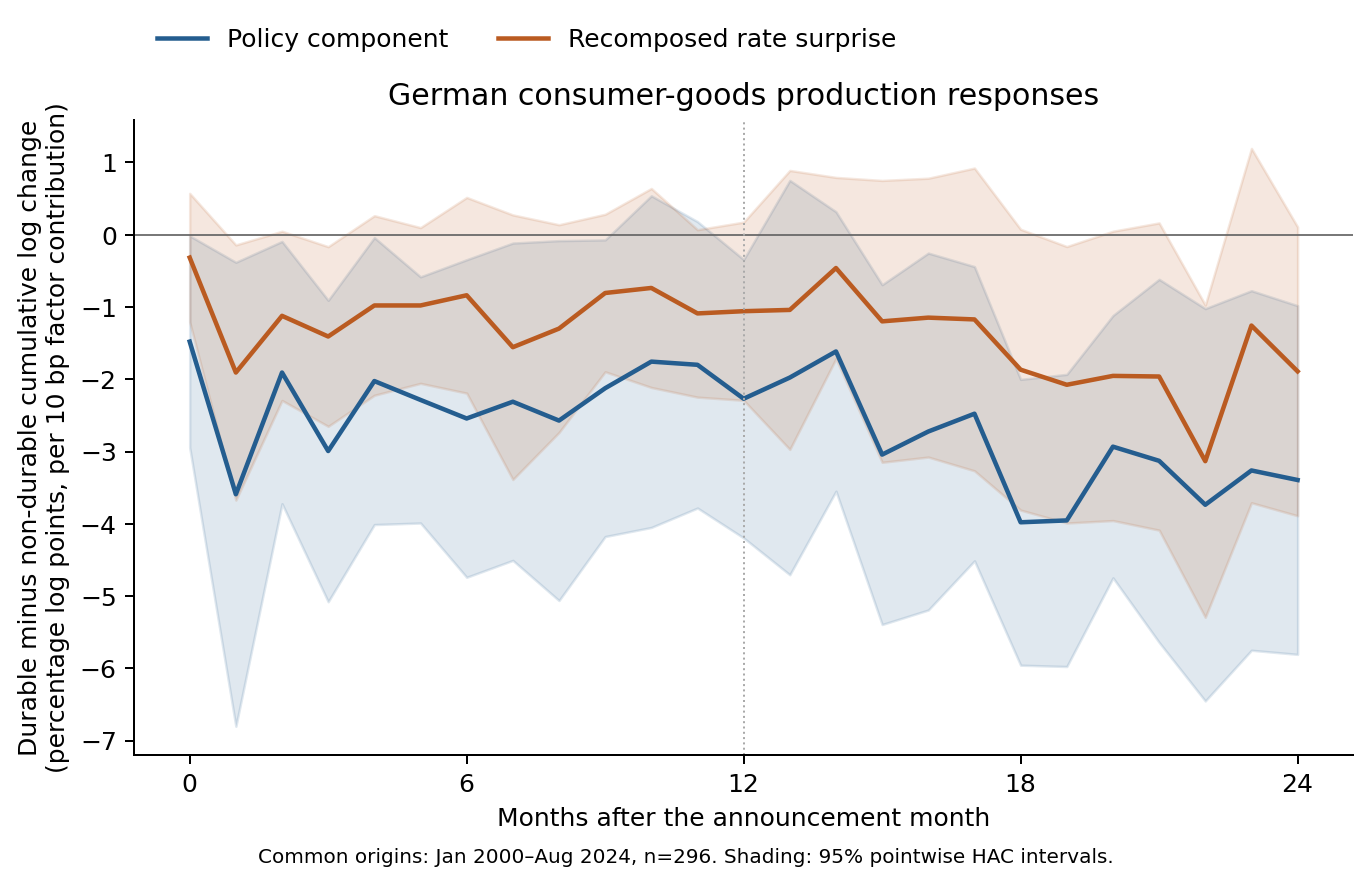

In [3]:
display(Image(filename=str(ROOT / "reports/notebook_replay/figures/response_paths.png")))

## 4. Declared sensitivities

The six-lag and poor-man comparisons retain the primary dates. The pre-pandemic comparison ends every outcome by December 2019, changing its historical target. The shorter and longer bandwidths change uncertainty while retaining the primary coefficients. These checks are sensitivity comparisons, rather than independent replications.

| Case | n | Gap | Lower | Upper |
| --- | ---: | ---: | ---: | ---: |
| primary | 308 | 1.261 | -0.107 | 3.309 |
| six lags | 308 | 1.170 | -0.161 | 3.131 |
| poor man | 308 | 1.226 | -1.024 | 4.189 |
| pre pandemic | 228 | 0.662 | -1.437 | 3.086 |
| short bandwidth | 308 | 1.261 | -0.079 | 3.266 |
| long bandwidth | 308 | 1.261 | -0.141 | 3.361 |

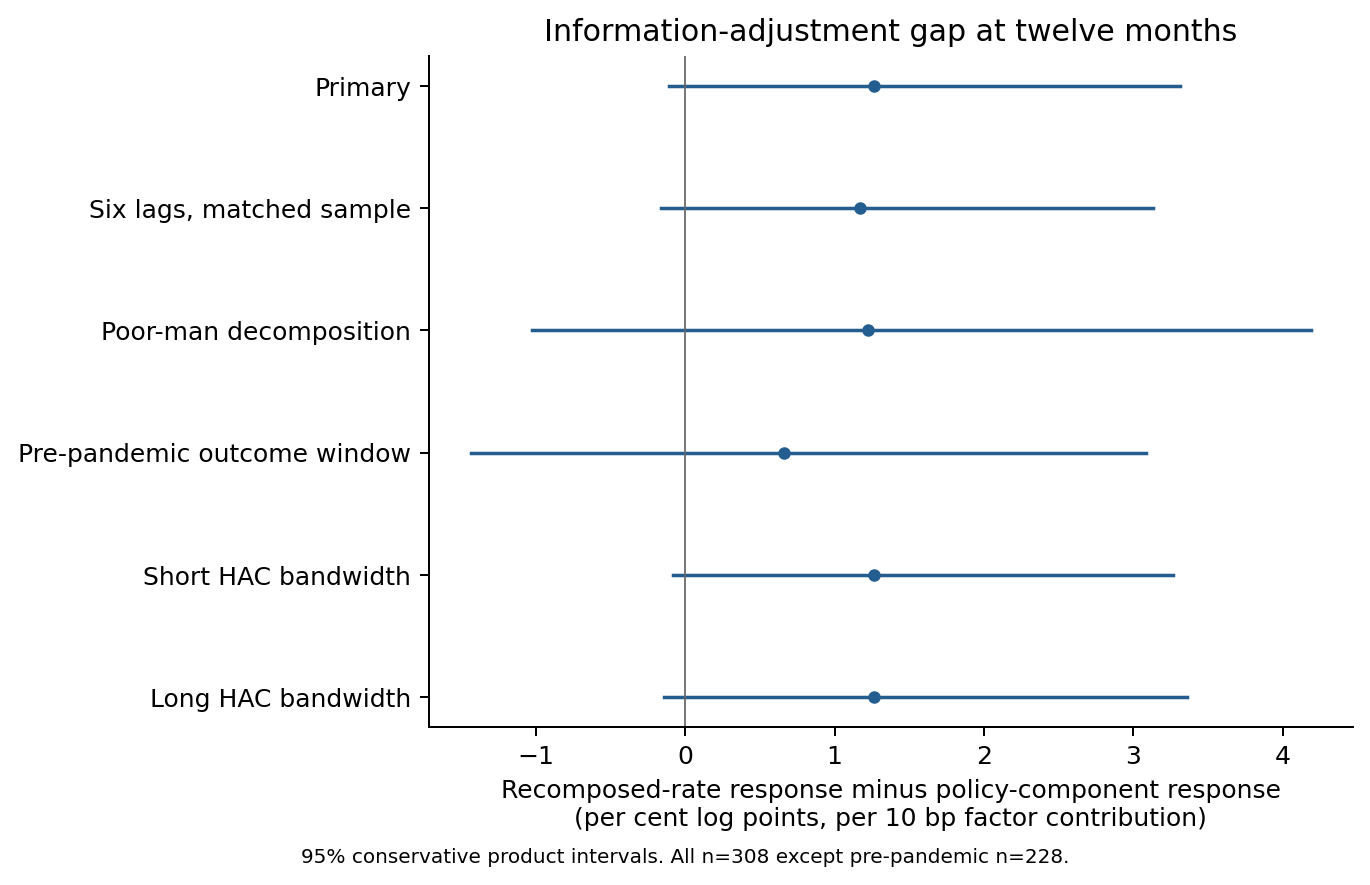

In [4]:
table = ["| Case | n | Gap | Lower | Upper |", "| --- | ---: | ---: | ---: | ---: |"]
for row in rows:
    if not row["case"].startswith("path_"):
        table.append(f"| {row['case'].replace('_', ' ')} | {row['n']} | {float(row['delta']):.3f} | {float(row['delta_product_low']):.3f} | {float(row['delta_product_high']):.3f} |")
display(Markdown("\n".join(table)))
display(Image(filename=str(ROOT / "reports/notebook_replay/figures/primary_sensitivity.png")))

## 5. Interpretation and scope

The supplied decomposition, factor and vintage are held fixed for these intervals; the regressor paths are not treated as fixed. The production groups exclude motor vehicles and do not measure household purchases. Passing numerical identities and independent R checks assesses implementation, without establishing exogeneity, a private-information mechanism or invariant responses across regimes. The [results note](../docs/results.md) records the estimates, influence and limitations; long derivations and specification departures belong in the paper appendix.